# Task 2 (level 2) : Rating Distribution Analysis

-           Load Cleaned Dataset

In [1]:
import pandas as pd
import matplotlib.pyplot as plt

df = pd.read_csv("dataset_level1_cleaned.csv")
df.head()


,Restaurant ID,Restaurant Name,Country Code,City,Address,Locality,Locality Verbose,Longitude,Latitude,Cuisines,...,Currency,Has Table booking,Has Online delivery,Is delivering now,Switch to order menu,Price range,Aggregate rating,Rating color,Rating text,Votes
0,6317637,Le Petit Souffle,162,Makati City,"Third Floor, Century City Mall, Kalayaan Avenu...","Century City Mall, Poblacion, Makati City","Century City Mall, Poblacion, Makati City, Mak...",121.027535,14.565443,"French, Japanese, Desserts",...,Botswana Pula(P),Yes,No,No,No,3,4.8,Dark Green,Excellent,314
1,6304287,Izakaya Kikufuji,162,Makati City,"Little Tokyo, 2277 Chino Roces Avenue, Legaspi...","Little Tokyo, Legaspi Village, Makati City","Little Tokyo, Legaspi Village, Makati City, Ma...",121.014101,14.553708,Japanese,...,Botswana Pula(P),Yes,No,No,No,3,4.5,Dark Green,Excellent,591
2,6300002,Heat - Edsa Shangri-La,162,Mandaluyong City,"Edsa Shangri-La, 1 Garden Way, Ortigas, Mandal...","Edsa Shangri-La, Ortigas, Mandaluyong City","Edsa Shangri-La, Ortigas, Mandaluyong City, Ma...",121.056831,14.581404,"Seafood, Asian, Filipino, Indian",...,Botswana Pula(P),Yes,No,No,No,4,4.4,Green,Very Good,270
3,6318506,Ooma,162,Mandaluyong City,"Third Floor, Mega Fashion Hall, SM Megamall, O...","SM Megamall, Ortigas, Mandaluyong City","SM Megamall, Ortigas, Mandaluyong City, Mandal...",121.056475,14.585318,"Japanese, Sushi",...,Botswana Pula(P),No,No,No,No,4,4.9,Dark Green,Excellent,365
4,6314302,Sambo Kojin,162,Mandaluyong City,"Third Floor, Mega Atrium, SM Megamall, Ortigas...","SM Megamall, Ortigas, Mandaluyong City","SM Megamall, Ortigas, Mandaluyong City, Mandal...",121.057508,14.584450,"Japanese, Korean",...,Botswana Pula(P),Yes,No,No,No,4,4.8,Dark Green,Excellent,229


-           Rating Distribution (Histogram)

This histogram shows how restaurant ratings are spread across the dataset.
Peaks in the graph indicate commonly received ratings.
This helps identify rating trends and biases.

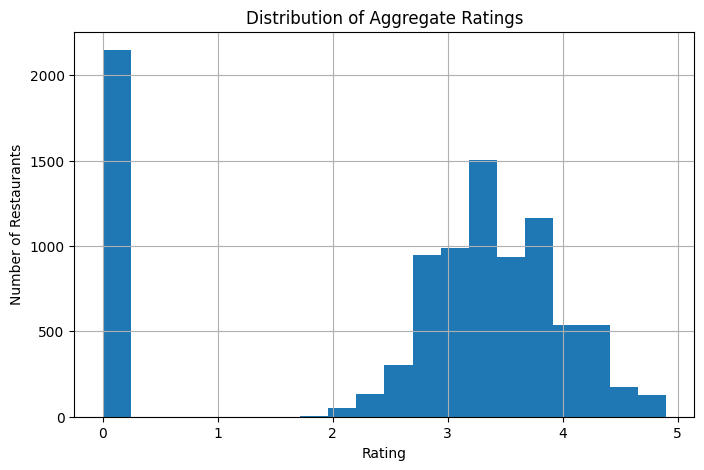

In [2]:
plt.figure(figsize=(8,5))
plt.hist(df['Aggregate rating'], bins=20)
plt.title("Distribution of Aggregate Ratings")
plt.xlabel("Rating")
plt.ylabel("Number of Restaurants")
plt.grid(True)
plt.show()


-           Most Common Rating Values

This shows which ratings are most frequent.
Many online food ratings tend to cluster around 3.5–4.5 due to positive review bias.

In [3]:
rating_counts = df['Aggregate rating'].value_counts().sort_index()
rating_counts


Aggregate rating
0.0    2148
1.8       1
1.9       2
2.0       7
2.1      15
2.2      27
2.3      47
2.4      87
2.5     110
2.6     191
2.7     250
2.8     315
2.9     381
3.0     468
3.1     519
3.2     522
3.3     483
3.4     498
3.5     480
3.6     458
3.7     427
3.8     400
3.9     335
4.0     266
4.1     274
4.2     221
4.3     174
4.4     144
4.5      95
4.6      78
4.7      42
4.8      25
4.9      61
Name: count, dtype: int64

Plot rating frequencies:

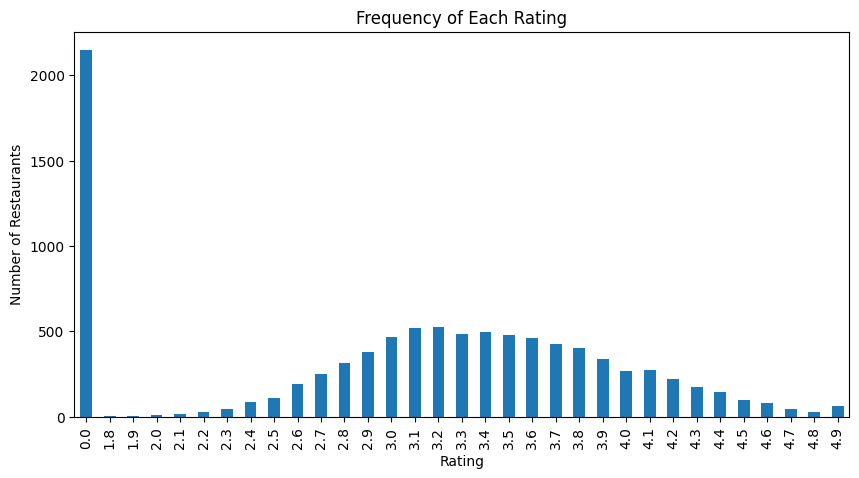

In [4]:
plt.figure(figsize=(10,5))
rating_counts.plot(kind='bar')
plt.title("Frequency of Each Rating")
plt.xlabel("Rating")
plt.ylabel("Number of Restaurants")
plt.show()


-           Average Rating by Country

This compares restaurant quality across countries based on mean ratings.
Some countries may consistently have higher/lower ratings due to cultural food preferences, customer expectations, or service standards.

In [5]:
country_rating = df.groupby('Country Code')['Aggregate rating'].mean().sort_values(ascending=False)
country_rating


Country Code
162    4.468182
208    4.300000
94     4.295238
148    4.262500
214    4.233333
189    4.210000
215    4.087500
166    4.060000
216    4.004378
191    3.870000
30     3.763333
14     3.658333
37     3.575000
184    3.575000
1      2.523324
Name: Aggregate rating, dtype: float64

Plot :

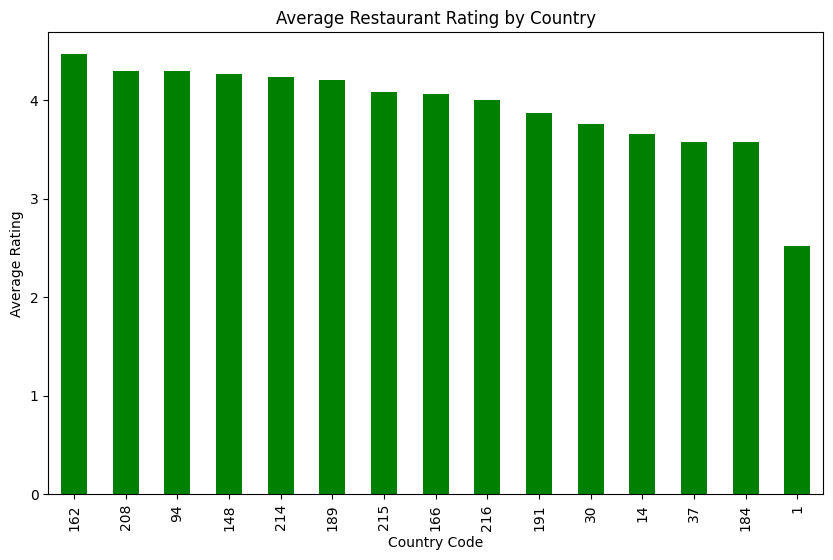

In [6]:
plt.figure(figsize=(10,6))
country_rating.plot(kind='bar', color='green')
plt.title("Average Restaurant Rating by Country")
plt.xlabel("Country Code")
plt.ylabel("Average Rating")
plt.show()


-           Rating by Price Range

This analysis checks if expensive restaurants receive better ratings.
Usually, higher price ranges tend to deliver better service and food quality.

In [7]:
price_rating = df.groupby('Price range')['Aggregate rating'].mean()
price_rating


Price range
1    1.999887
2    2.941054
3    3.683381
4    3.817918
Name: Aggregate rating, dtype: float64

Plot :

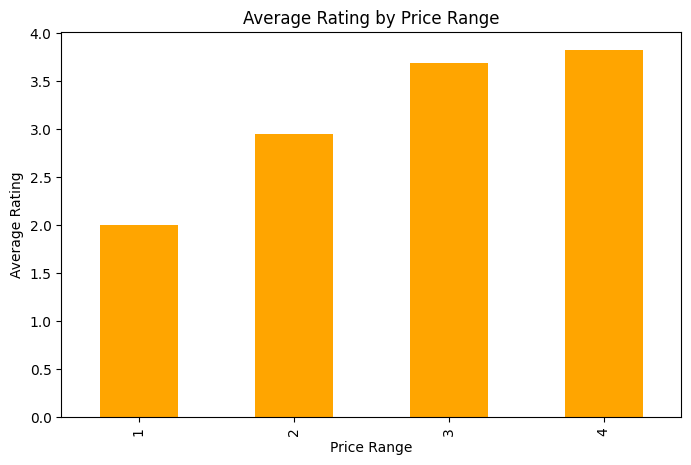

In [8]:
plt.figure(figsize=(8,5))
price_rating.plot(kind='bar', color='orange')
plt.title("Average Rating by Price Range")
plt.xlabel("Price Range")
plt.ylabel("Average Rating")
plt.show()


-           Advanced: Boxplot of Ratings by Price Range

Boxplots help us understand the spread, median, and outliers for each price category.
This quickly shows whether higher-priced restaurants consistently maintain higher ratings.

<Figure size 800x500 with 0 Axes>

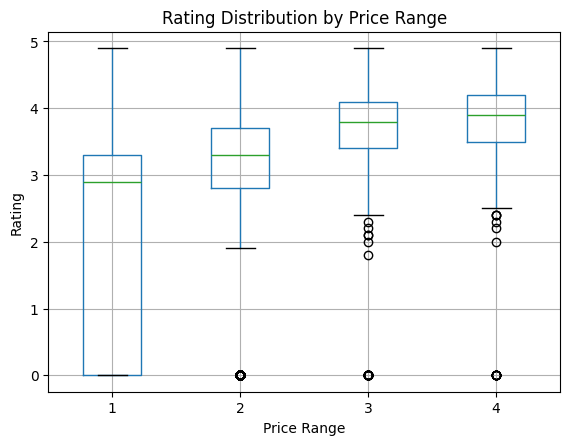

In [9]:
plt.figure(figsize=(8,5))
df.boxplot(column='Aggregate rating', by='Price range')
plt.title("Rating Distribution by Price Range")
plt.suptitle("")
plt.xlabel("Price Range")
plt.ylabel("Rating")
plt.show()


# Summary :
8 Most ratings fall between 3.5 and 4.5

(typical for restaurant datasets)

* Most common ratings

From your bar chart, identify the top 3 rating values.

* Country-wise rating differences exist

Some countries have higher average ratings.

* Higher price range → Higher average rating

(show exact values from your output).

* Rating distribution is slightly right-skewed

More restaurants score on the high side.